# Разведочный анализ данных: начало

**Выполнил:** Подольский Филипп, магистратура ПМИ, ФМИ ПГНИУ.
Дисциплина «Разведочный анализ и алгоритмы классификации» (Барулина М. А.), практика «Разведочный анализ данных: начало».

Текст и код преподавателя сохранены. Мои решения записаны в ячейки, где было «# ваш код здесь», а после каждого задания идёт блок **«Ответ»**: число с нужным округлением и короткое пояснение. Как требовалось на курсе, на этапе EDA я только описываю то, что видно в данных, и не делаю выводов о том, что одна характеристика «влияет» на другую.

**Что поправлено, чтобы тетрадка запускалась вне Colab (Python 3.13, pandas 3, seaborn 0.13):**

1. Подключение Google Drive (`drive.mount`) убрано. Путь к данным теперь относительный: `../data/diamonds_good.csv`, это тот же файл, что раздавала преподаватель.
2. `df['depth'].fillna(median_depth, inplace=True)` заменено на `df['depth'] = df['depth'].fillna(median_depth)`. В pandas 3 действует Copy-on-Write: `inplace` у столбца, взятого через `df['depth']`, меняет временную копию, а не саму таблицу, поэтому пропуски в `depth` остались бы на месте без всякой ошибки. В Colab на pandas 2 строка ещё работала, хотя и выдавала FutureWarning.
3. `df.describe(include='object')` заменено на `include='str'`, потому что в pandas 3 текстовые столбцы по умолчанию имеют тип `str`, а не `object`.
4. В `sns.barplot(..., palette=...)` добавлены `hue='cut', legend=False`: палитра без `hue` в seaborn 0.13 объявлена устаревшей. Сам график не меняется.
5. Pandas profiling (`ydata-profiling` 4.18) под Python 3.13 ставится, но тянет pandas < 3, matplotlib ≤ 3.10 и scipy < 1.17, то есть ломает окружение всего репозитория. Поэтому отчёт построен заранее скриптом `make_profile_report.py` в отдельном окружении и лежит рядом с тетрадкой: **`Diamonds_report.html`**. В тетрадке вместо него сделан короткий ручной обзор тех же сведений.

Мы будем работать с датасетом про алмазы - в нем содержатся их различные характеристики, а также стоимость.

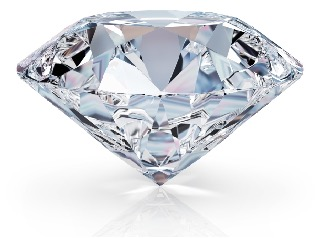

[Интересная статья про качество алмазов](https://www.diamonds.pro/education/diamond-depth-and-table/)

**Цели на сегодня:**

* понять влияние различных характеристик алмазов на их качество и стоимость

* научиться делать разведочный анализ данных

* изучить библиотеки pandas, numpy и matplotlib, seaborn

[Pandas cheatsheet](https://images.datacamp.com/image/upload/v1676302204/Marketing/Blog/Pandas_Cheat_Sheet.pdf)

## Импорт библиотек и загрузка данных

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

*(В Colab здесь подключался Google Drive: `from google.colab import drive; drive.mount('/content/drive')`. В репозитории файл лежит в папке `data/`, поэтому ячейка не нужна.)*

In [2]:
DIAMONDS_DATASET = "../data/diamonds_good.csv"   # в Colab: /content/drive/MyDrive/data/eda/diamonds_good.csv

In [3]:
df = pd.read_csv(DIAMONDS_DATASET)

## Описание данных

* `carat` - число каратов алмаза
* `cut` - огранка алмаза
* `color` - цвет алмаза
* `clarity` - прозрачность алмаза
* `depth` - глубина алмаза
* `table` - платформа алмаза (грань, которую можно увидеть, если смотреть на камень лицевой стороной вверх)
* `price` - цена алмаза
* `x` - размер алмаза по оси x
* `y` - размер алмаза по оси y
* `z` - размер алмаза по оси z

In [4]:
df.head(10)

,carat,cut,color,clarity,depth,table,price,'x','y','z'
0,0.23,Ideal,E,SI2,61.5,55.0,326.0,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326.0,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327.0,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334.0,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335.0,4.34,4.35,2.75
5,NaN,Very Good,J,VVS2,62.8,57.0,336.0,3.94,3.96,2.48
6,0.24,Very Good,I,VVS1,62.3,57.0,336.0,3.95,3.98,2.47
7,0.26,Very Good,H,SI1,61.9,55.0,337.0,4.07,4.11,2.53
8,0.22,Fair,E,VS2,65.1,61.0,337.0,3.87,3.78,2.49
9,0.23,Very Good,H,VS1,59.4,61.0,338.0,4.00,4.05,2.39


In [5]:
df.tail()

,carat,cut,color,clarity,depth,table,price,'x','y','z'
53935,0.72,Ideal,D,SI1,60.8,57.0,2757.0,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757.0,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757.0,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757.0,6.15,6.12,3.74
53939,0.75,Ideal,D,SI2,62.2,55.0,2757.0,5.83,5.87,3.64


In [6]:
df.sample(3)

,carat,cut,color,clarity,depth,table,price,'x','y','z'
34784,0.4,Very Good,G,VS1,62.8,56.0,877.0,4.67,4.70,2.94
12830,1.0,Very Good,E,SI1,59.6,60.0,5351.0,6.43,6.48,3.85
3871,0.9,Very Good,H,SI2,61.2,57.0,3481.0,6.21,6.27,3.82


## Исследование данных

Размер датасета

In [7]:
df.shape

(53940, 10)

Информация о типах данных и пропусках

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53442 non-null  float64
 1   cut      53940 non-null  str    
 2   color    53940 non-null  str    
 3   clarity  53940 non-null  str    
 4   depth    52950 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  float64
 7   'x'      53940 non-null  float64
 8   'y'      53935 non-null  float64
 9   'z'      53940 non-null  float64
dtypes: float64(7), str(3)
memory usage: 4.1 MB


Основные числовые характеристики

In [9]:
df.describe()

,carat,depth,table,price,'x','y','z'
count,53442.000000,52950.000000,53940.000000,53940.000000,53940.000000,53935.000000,53940.000000
mean,0.797561,61.749422,57.457184,3932.799722,5.731157,5.734469,3.538734
std,0.473534,1.431558,2.234491,3989.439738,1.121761,1.142125,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [10]:
df.describe(include='str')   # в Colab было include='object'; в pandas 3 текстовые столбцы имеют тип str

,cut,color,clarity
count,53940,53940,53940
unique,6,7,8
top,Ideal,G,SI1
freq,21524,11292,13065


In [11]:
df.describe(include='all')

,carat,cut,color,clarity,depth,table,price,'x','y','z'
count,53442.000000,53940,53940,53940,52950.000000,53940.000000,53940.000000,53940.000000,53935.000000,53940.000000
unique,NaN,6,7,8,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Ideal,G,SI1,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,21524,11292,13065,NaN,NaN,NaN,NaN,NaN,NaN
mean,0.797561,NaN,NaN,NaN,61.749422,57.457184,3932.799722,5.731157,5.734469,3.538734
std,0.473534,NaN,NaN,NaN,1.431558,2.234491,3989.439738,1.121761,1.142125,0.705699
min,0.200000,NaN,NaN,NaN,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,NaN,NaN,NaN,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,NaN,NaN,NaN,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,NaN,NaN,NaN,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000


In [12]:
df.duplicated().sum()

np.int64(135)

In [13]:
# df[условие фильтрации]

In [14]:
df[df.duplicated()]

,carat,cut,color,clarity,depth,table,price,'x','y','z'
1005,0.79,Ideal,G,SI1,62.3,57.0,2898.0,5.90,5.85,3.66
1006,0.79,Ideal,G,SI1,62.3,57.0,2898.0,5.90,5.85,3.66
1007,0.79,Ideal,G,SI1,62.3,57.0,2898.0,5.90,5.85,3.66
1008,0.79,Ideal,G,SI1,62.3,57.0,2898.0,5.90,5.85,3.66
2025,1.52,Good,E,I1,57.3,58.0,3105.0,7.53,7.42,4.28
...,...,...,...,...,...,...,...,...,...,...
47969,0.52,Ideal,D,VS2,61.8,55.0,1919.0,5.19,5.16,3.20
49326,0.51,Ideal,F,VVS2,61.2,56.0,2093.0,5.17,5.19,3.17
49557,0.71,Good,F,SI2,64.1,60.0,2130.0,0.00,0.00,0.00
50079,0.51,Ideal,F,VVS2,61.2,56.0,2203.0,5.19,5.17,3.17


In [15]:
# df = df.drop_duplicates()

df.drop_duplicates(inplace=True)

df.shape

(53805, 10)

In [16]:
df.reset_index(inplace=True, drop=True)

df.head()

,carat,cut,color,clarity,depth,table,price,'x','y','z'
0,0.23,Ideal,E,SI2,61.5,55.0,326.0,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326.0,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327.0,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334.0,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335.0,4.34,4.35,2.75


In [17]:
df.head()

,carat,cut,color,clarity,depth,table,price,'x','y','z'
0,0.23,Ideal,E,SI2,61.5,55.0,326.0,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326.0,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327.0,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334.0,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335.0,4.34,4.35,2.75


## Работа с пропущенными значениями

Стратегии заполнения пропусков:

* если пропусков очень мало (~меньше процента) - строки с пропусками можно удалить или заполнить средним/медианой

* если пропусков мало (~5-10%) - их можно заполнить (средним, медианой, уникальным значением, самым популярным значением, спрогнозировать)

* если пропусков много - можно удалить столбец

* можно пытаться предсказывать пропуски моделью

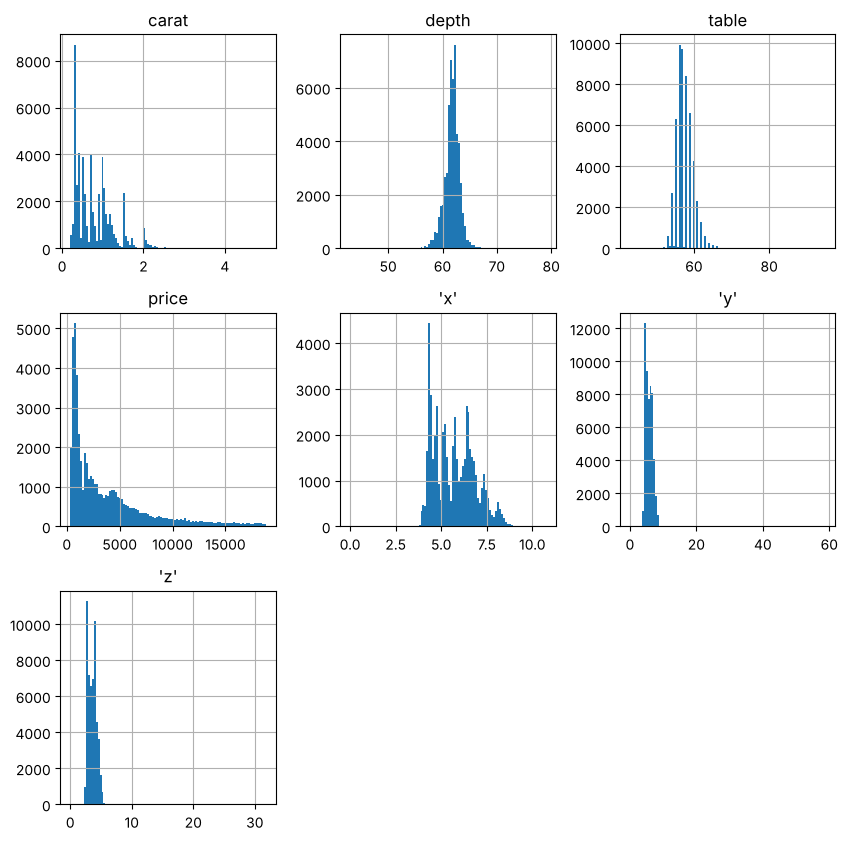

In [18]:
df[["carat","depth","table","price","'x'","'y'","'z'"]].hist(bins=100, figsize=(10,10));

In [19]:
median_carat = df['carat'].median()

df.fillna({'carat': median_carat}, inplace=True);   # ';' — в pandas 3 inplace-методы возвращают сам df, иначе выведется вся таблица

In [20]:
median_depth = df['depth'].median()
depth_filled = df['depth'].isna()     # запомним, какие строки заполняем (пригодится в задании 3)

# в Colab было: df['depth'].fillna(median_depth, inplace=True)
# в pandas 3 (Copy-on-Write) inplace-метод у столбца меняет копию, а не df, поэтому присваиваем явно
df['depth'] = df['depth'].fillna(median_depth)

### Задание 1

Заполните пропуски в столбце `y` медианным значением. Чему равно это значение? Ответ округлите до сотых.

In [21]:
print('Пропусков в y до заполнения:', df["'y'"].isna().sum())

median_y = df["'y'"].median()
df["'y'"] = df["'y'"].fillna(median_y)

print('Медиана y:', round(median_y, 2))
print('Пропусков во всей таблице после заполнения carat, depth и y:', df.isna().sum().sum())

Пропусков в y до заполнения: 5
Медиана y: 5.71
Пропусков во всей таблице после заполнения carat, depth и y: 0


**Ответ: 5.71.**

Медиану `y` я считал уже после удаления дубликатов. Пропусков в `y` всего 5 из 53 805 строк, так что заполнение почти не меняет распределение. Медиана удобнее среднего, потому что у размеров есть явные выбросы: по `describe()` минимум `y` равен 0, а максимум 58.9 мм при типичных 4–9 мм, и на медиану они не влияют. После этого шага пропусков в таблице не осталось.

## Однофакторный анализ

### Число карат

* мелкие — массой до 0,30 карат (не включительно);
* средние — массой от 0,30 до 1 карат (не включительно);
* крупные – 1 карат и выше, называют солитеры.


Небольшие бриллианты различного размера, полученные при огранке алмаза, и весящие каждый в отдельности менее 0,25 карат, называют *melee (мили)*. Полученные таким же путем более крупные бриллианты различного размера называют *melange (меланж)*.


Бриллианты более 6 карат обычно продаются c аукционов.


Алмазам и бриллиантам более 25 карат присваивают собственные имена.

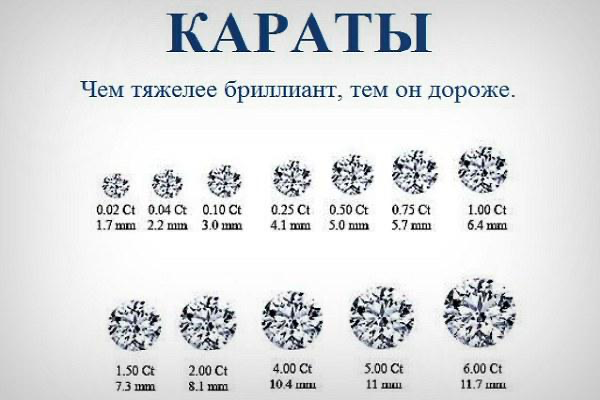

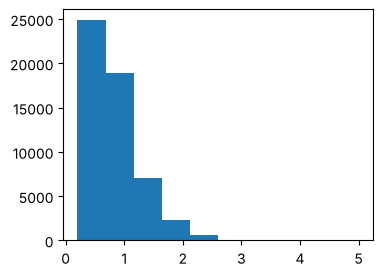

In [22]:
plt.figure(figsize=(4,3))

plt.hist(df.carat);

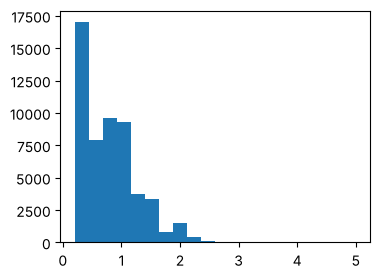

In [23]:
plt.figure(figsize=(4,3))

plt.hist(df.carat, bins=20);

Сколько карат весит самый тяжелый бриллиант в датасете? А самый легкий?

In [24]:
df.carat.min(), df.carat.max()

(np.float64(0.2), np.float64(5.01))

Сколько мелких бриллиантов в датасете?

In [25]:
len(df[df.carat < 0.3])

1582

Сколько процентов бриллиантов среди всего датасета - крупные?

In [26]:
100 * len(df[df.carat >= 1]) / len(df)

35.00046464083264

Посмотрим как число карат влияет на стоимость алмаза

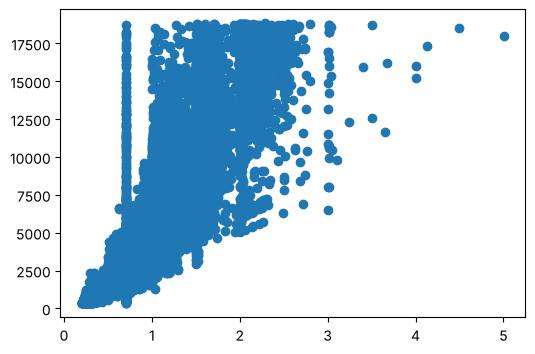

In [27]:
plt.figure(figsize=(6,4))

plt.scatter(df.carat, df.price);

In [28]:
np.corrcoef(df.carat, df.price)[0][1]

np.float64(0.9164989435440213)

### Cut (огранка алмаза)

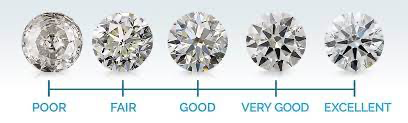

In [29]:
df['cut'].value_counts(normalize=True)

cut
Ideal        0.398941
Premium      0.255088
Very Good    0.224013
Good         0.090772
Fair         0.029700
Goood        0.001487
Name: proportion, dtype: float64

In [30]:
df['cut'] = df['cut'].replace('Goood', 'Good')

In [31]:
df['cut'].value_counts()   # проверка: опечатка Goood объединена с Good, осталось 5 огранок

cut
Ideal        21465
Premium      13725
Very Good    12053
Good          4964
Fair          1598
Name: count, dtype: int64

Посмотрим как влияет огранка алмаза на его стоимость

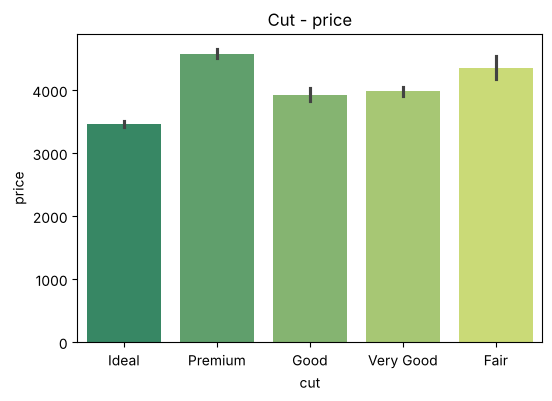

In [32]:
plt.figure(figsize=(6,4))

# в Colab: sns.barplot(x='cut', y='price', data=df, palette='summer') — палитра без hue устарела в seaborn 0.13
sns.barplot(x='cut', y='price', hue='cut', data=df, palette='summer', legend=False)
plt.title('Cut - price')
plt.show();

### Задание 2

Какое максимальное число карат весит алмаз огранки `Fair`?
Ответ округлите до сотых.

Максимальный вес алмаза огранки Fair: 5.01 карат
Медианный вес по огранкам: {'Fair': 0.99, 'Good': 0.8, 'Ideal': 0.54, 'Premium': 0.82, 'Very Good': 0.71}


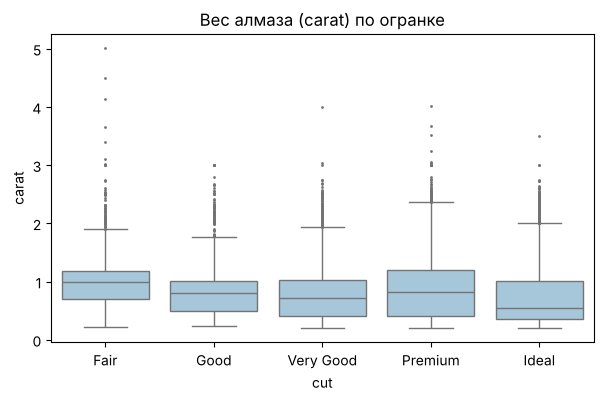

In [33]:
max_carat_fair = df.loc[df['cut'] == 'Fair', 'carat'].max()
print('Максимальный вес алмаза огранки Fair:', round(max_carat_fair, 2), 'карат')
print('Медианный вес по огранкам:', df.groupby('cut')['carat'].median().to_dict())

# порядок огранок от худшей к лучшей — у этого признака порядок очевиден
cut_order = ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal']

plt.figure(figsize=(7, 4))
sns.boxplot(x='cut', y='carat', data=df, order=cut_order, color='#9ecae1', fliersize=1)
plt.title('Вес алмаза (carat) по огранке')
plt.ylabel('carat')
plt.show()

**Ответ: 5.01.**

Это одновременно и максимум по всему датасету (`df.carat.max()` выше): самый тяжёлый камень в данных огранки Fair. На диаграмме размаха у Fair самая высокая медиана веса (0.99 карата), а у Ideal самая низкая (0.54). Это сходится с таблицей ниже, где средний вес у Fair 1.04 карата, у Ideal 0.70. Пока это только описание состава групп.

Посчитаем среднюю стоимость алмазов в каждой категории

In [34]:
df.groupby('cut')['price'].mean()

cut
Fair         4347.735294
Good         3926.266317
Ideal        3462.593850
Premium      4581.864918
Very Good    3982.162781
Name: price, dtype: float64

Посчитаем несколько характеристик в зависимости от огранки

In [35]:
df.groupby('cut').agg(PriceMean=('price','mean'),
                      PriceMedian=('price', 'median'),
                      CaratMean=('carat', 'mean'))

,PriceMean,PriceMedian,CaratMean
cut,,,
Fair,4347.735294,3282.0,1.040094
Good,3926.266317,3029.5,0.845796
Ideal,3462.593850,1813.0,0.703331
Premium,4581.864918,3175.0,0.889616
Very Good,3982.162781,2649.0,0.804177


In [36]:
df.groupby('cut').agg(PriceMean=('price','mean'),
                      PriceMedian=('price', 'median'),
                      CaratMean=('carat', 'mean')).sort_values(by='PriceMean', ascending=False)

,PriceMean,PriceMedian,CaratMean
cut,,,
Premium,4581.864918,3175.0,0.889616
Fair,4347.735294,3282.0,1.040094
Very Good,3982.162781,2649.0,0.804177
Good,3926.266317,3029.5,0.845796
Ideal,3462.593850,1813.0,0.703331


## Table and Depth

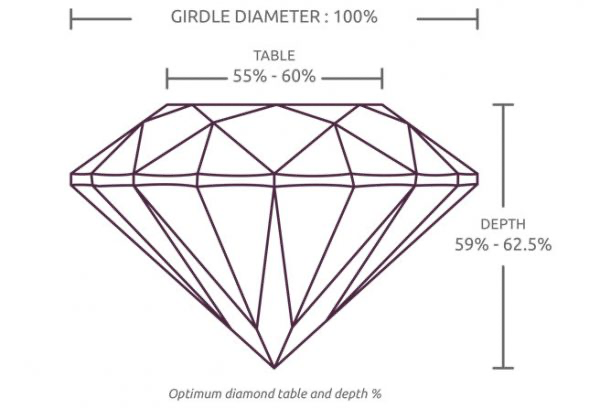

Оптимальное значение параметра `table` для алмаза [55%; 60%].

Какая доля алмазов в данных имеют оптимальное значение `table`?

In [37]:
len(df[(df.table >= 55) & (df.table <= 60)]) / len(df)

0.8439364371340954

### Задание 3

Оптимальное значение параметра `depth` для алмаза [59%; 62.5%].

Какая доля алмазов в данных имеют одновременно оптимальное значение `table` и `depth`?

Ответ округлите до сотых.

Доля с оптимальным table:           0.8439
Доля с оптимальным depth:           0.7279
Доля с оптимальными table и depth:  0.6206 → 0.62
Из них строк, где depth был пропущен и заполнен медианой 61.8 : 838
Вне оптимальной зоны: 20412 | из них depth > 62.5: 12798 | depth < 59: 1845 | table вне [55; 60]: 8397


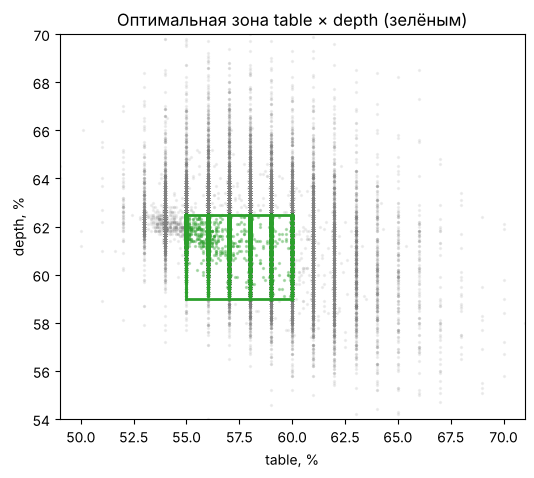

In [38]:
opt_table = (df['table'] >= 55) & (df['table'] <= 60)
opt_depth = (df['depth'] >= 59) & (df['depth'] <= 62.5)
opt_both = opt_table & opt_depth

print('Доля с оптимальным table:          ', round(opt_table.mean(), 4))
print('Доля с оптимальным depth:          ', round(opt_depth.mean(), 4))
print('Доля с оптимальными table и depth: ', round(opt_both.mean(), 4), '→', round(opt_both.mean(), 2))
print('Из них строк, где depth был пропущен и заполнен медианой', median_depth, ':',
      (opt_both & depth_filled).sum())
outside = ~opt_both
print('Вне оптимальной зоны:', outside.sum(), '| из них depth > 62.5:', (outside & (df['depth'] > 62.5)).sum(),
      '| depth < 59:', (outside & (df['depth'] < 59)).sum(), '| table вне [55; 60]:', (outside & ~opt_table).sum())

# положение алмазов на плоскости (table, depth); рамка — оптимальная зона
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(df.loc[~opt_both, 'table'], df.loc[~opt_both, 'depth'], s=2, alpha=0.1, c='tab:gray')
ax.scatter(df.loc[opt_both, 'table'], df.loc[opt_both, 'depth'], s=2, alpha=0.3, c='tab:green')
ax.add_patch(plt.Rectangle((55, 59), 5, 3.5, fill=False, ec='tab:green', lw=2))
ax.set_xlim(49, 71); ax.set_ylim(54, 70)   # единичные выбросы за пределами окна не показаны
ax.set(xlabel='table, %', ylabel='depth, %', title='Оптимальная зона table × depth (зелёным)')
plt.show()

**Ответ: 0.62** (62.1 % алмазов).

Каждое условие записано как логическая маска, пересечение берётся оператором `&`, а среднее по булевой маске и есть доля. Оптимальный `table` у 84.4 % камней, оптимальный `depth` у 72.8 %, оба сразу у 62.1 %. На диаграмме видно, что `table` почти всегда принимает целые значения (вертикальные полосы). За пределами оптимальной зоны чаще всего оказываются камни с `depth` больше 62.5 (12 798 из 20 412), реже камни с `table` вне [55; 60] (8 397).

Тонкость: 838 строк из этой доли — бывшие пропуски `depth`. Они заполнены медианой 61.8, а она попадает в оптимальный интервал. Без заполнения доля была бы немного меньше.

### Задание 4

Сравните медианную стоимость всех алмазов, и алмазов с оптимальными table & depth. Какая больше?

Медианная стоимость всех алмазов:                      2401.0
Медианная стоимость алмазов с оптимальными table/depth: 2215.0
Больше медиана: всех алмазов


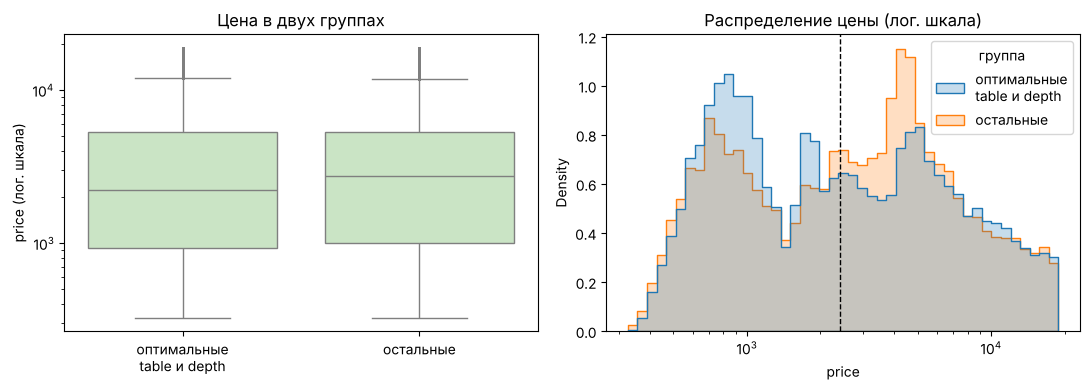

In [39]:
median_all = df['price'].median()
median_opt = df.loc[opt_both, 'price'].median()
print('Медианная стоимость всех алмазов:                     ', median_all)
print('Медианная стоимость алмазов с оптимальными table/depth:', median_opt)
print('Больше медиана:', 'всех алмазов' if median_all > median_opt else 'алмазов с оптимальными table и depth')

group = pd.Series(np.where(opt_both, 'оптимальные\ntable и depth', 'остальные'), index=df.index, name='группа')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(x=group, y=df['price'], ax=axes[0], color='#c7e9c0', fliersize=1)
axes[0].set_yscale('log'); axes[0].set(xlabel='', ylabel='price (лог. шкала)', title='Цена в двух группах')
sns.histplot(x=df['price'], hue=group, stat='density', common_norm=False, element='step',
             log_scale=True, ax=axes[1])
axes[1].axvline(median_all, color='k', ls='--', lw=1, label='медиана всех')
axes[1].set(title='Распределение цены (лог. шкала)')
plt.tight_layout(); plt.show()

**Ответ: медианная стоимость всех алмазов больше: 2401 против 2215.**

На логарифмической шкале у распределения цены в обеих группах несколько пиков. У группы с оптимальными `table` и `depth` выше пик дешёвых камней (около 700–1000), а у остальных выделяется пик около 4000–5000, отсюда и разница медиан. Я фиксирую только это: «оптимальные» пропорции в этих данных не сопровождаются более высокой медианной ценой. Почему так, по одной медиане сказать нельзя, ведь группы могут различаться и весом, и другими характеристиками.

Вычислите корреляцию `table` и `price`, а затем `depth`и `price`. Какой параметр влияет на цену больше?

In [40]:
np.corrcoef(df.table, df.price)[0][1]

np.float64(0.12662153885758182)

In [41]:
np.corrcoef(df.depth, df.price)[0][1]

np.float64(-0.01083161422683723)

**Ответ на вопрос.** |r(table, price)| = 0.127 > |r(depth, price)| = 0.011, то есть линейная связь с ценой у `table` заметнее, но обе связи очень слабые. Коэффициент Пирсона показывает только, насколько согласованно две величины меняются по прямой. Что на что «влияет», он не говорит, поэтому вопрос я понимаю как «что сильнее коррелирует с ценой».

## Clarity - прозрачность алмаза

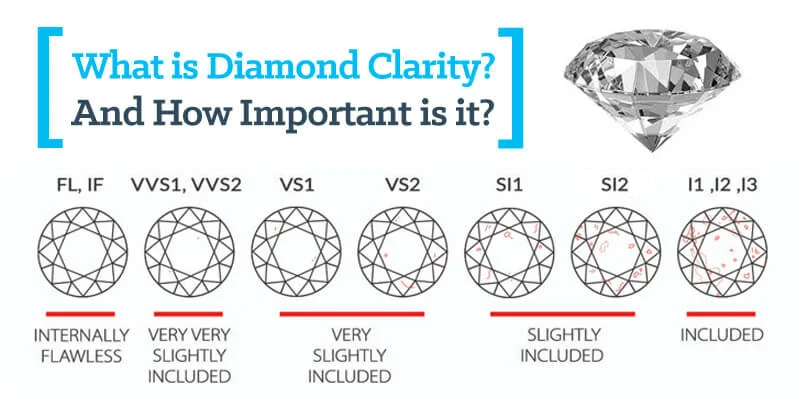

### Задание 5

Сколько различных градаций есть в столбце `clarity`?

In [42]:
print('Число градаций clarity:', df['clarity'].nunique())
print(df['clarity'].unique().tolist())

Число градаций clarity: 8
['SI2', 'SI1', 'VS1', 'VS2', 'VVS2', 'VVS1', 'I1', 'IF']


**Ответ: 8 градаций.** По схеме выше от худшей к лучшей это I1, SI2, SI1, VS2, VS1, VVS2, VVS1, IF. Градаций FL, I2 и I3 со схемы в данных нет. У признака очевидный порядок, поэтому дальше я рисую категории именно в нём, а не по алфавиту.

### Задание 6

Сколько алмазов в таблице, относящихся к категории `very very slightly included`?

VVS1: 3648 | VVS2: 5056 | всего VVS: 8704


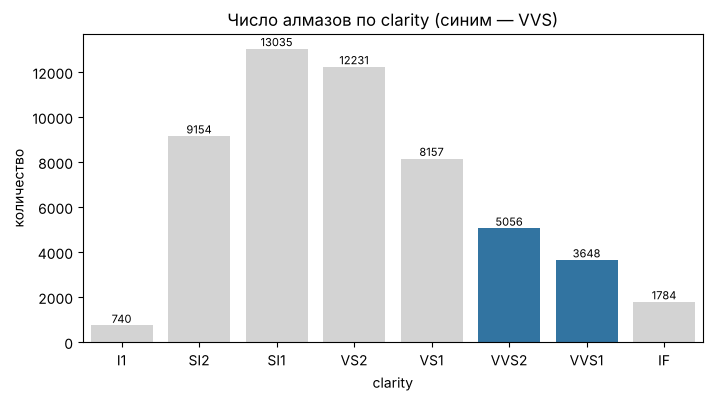

In [43]:
clarity_order = ['I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', 'IF']   # от худшей к лучшей

vvs = df['clarity'].isin(['VVS1', 'VVS2'])     # very very slightly included = VVS1 + VVS2
print('VVS1:', (df['clarity'] == 'VVS1').sum(), '| VVS2:', (df['clarity'] == 'VVS2').sum(),
      '| всего VVS:', vvs.sum())

plt.figure(figsize=(8, 4))
ax = sns.countplot(x='clarity', data=df, order=clarity_order, hue='clarity', hue_order=clarity_order,
                   palette=['tab:blue' if c.startswith('VVS') else 'lightgray' for c in clarity_order],
                   legend=False)
for cont in ax.containers:
    ax.bar_label(cont, fontsize=8)
ax.set(title='Число алмазов по clarity (синим — VVS)', ylabel='количество')
plt.show()

**Ответ: 8704 алмаза.** По схеме категория *very very slightly included* состоит из двух градаций, VVS1 (3648 шт.) и VVS2 (5056 шт.), поэтому я считаю их вместе через `isin`. Чаще всего в данных встречаются средние градации SI1 и VS2, реже всего крайние I1 и IF.

### Задание 7

Нарисуйте график зависимости цены алмазов от `clarity`. Алмазы какой категории в наших данных стоят дороже остальных?

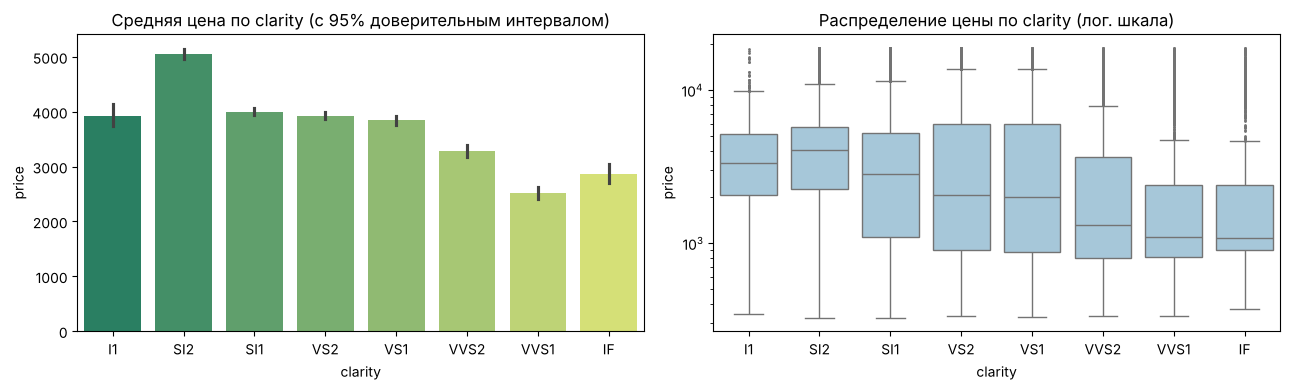

,PriceMean,PriceMedian,CaratMedian,Count
clarity,,,,
I1,3925.28,3346.0,1.10,740
SI2,5060.74,4072.0,1.01,9154
SI1,3996.48,2822.0,0.75,13035
VS2,3927.25,2057.0,0.67,12231
VS1,3841.27,2010.0,0.58,8157
VVS2,3286.53,1316.0,0.44,5056
VVS1,2526.13,1094.0,0.40,3648
IF,2870.57,1080.0,0.35,1784


In [44]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(x='clarity', y='price', data=df, order=clarity_order, hue='clarity', hue_order=clarity_order,
            palette='summer', legend=False, ax=axes[0])
axes[0].set_title('Средняя цена по clarity (с 95% доверительным интервалом)')
sns.boxplot(x='clarity', y='price', data=df, order=clarity_order, color='#9ecae1', fliersize=1, ax=axes[1])
axes[1].set_yscale('log'); axes[1].set_title('Распределение цены по clarity (лог. шкала)')
plt.tight_layout(); plt.show()

clarity_stats = (df.groupby('clarity')
                   .agg(PriceMean=('price', 'mean'), PriceMedian=('price', 'median'),
                        CaratMedian=('carat', 'median'), Count=('price', 'size'))
                   .loc[clarity_order].round(2))
clarity_stats

**Ответ: SI2.** У SI2 и самая высокая средняя цена (5060.7), и самая высокая медианная (4072).

Что видно на графиках: средняя цена не растёт вместе с качеством прозрачности. У лучших градаций IF и VVS1 она самая низкая (2870.6 и 2526.1), а дороже всех SI2. В таблице заметно, что группы сильно различаются и весом: медианный вес у SI2 1.01 карата, у IF всего 0.35. По одному графику «цена ~ clarity» нельзя утверждать, что прозрачность как-то действует на цену, потому что здесь сравниваются группы с разным составом.

### Задание 8

Для каждой пары значений категорий (`cut`,`clarity`) вычислим среднюю и медианную стоимость. Результат отсортируем по убыванию средней стоимости.

Алмазы какой огранки (`cut`) в совокупностью с некоторой категорией `clarity` имеют наибольшую среднюю стоимость?

PriceMean  PriceMedian  Count
cut       clarity                               
Premium   SI2         5556.3       4292.5   2922
Fair      SI2         5145.7       3681.0    458
Very Good SI2         4988.7       4042.0   2096
Ideal     SI2         4761.7       4068.0   2593
Good      SI2         4544.1       3763.0   1085
Premium   VS2         4539.4       2724.0   3342
          VS1         4491.2       2362.0   1982
          SI1         4451.9       3618.0   3562
Very Good IF          4373.3       1708.0    267
Ideal     I1          4335.7       3673.5    146

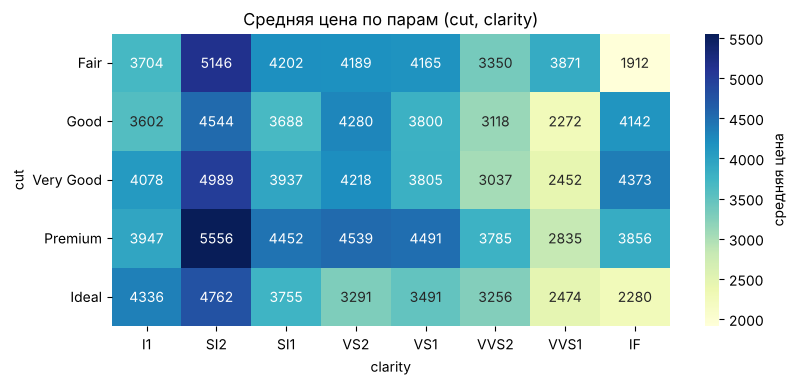

In [45]:
cut_clarity = (df.groupby(['cut', 'clarity'])
                 .agg(PriceMean=('price', 'mean'), PriceMedian=('price', 'median'), Count=('price', 'size'))
                 .sort_values(by='PriceMean', ascending=False))
display(cut_clarity.head(10).round(1))

pivot = (df.pivot_table(index='cut', columns='clarity', values='price', aggfunc='mean')
           .loc[cut_order, clarity_order])
plt.figure(figsize=(9, 3.8))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='YlGnBu', cbar_kws={'label': 'средняя цена'})
plt.title('Средняя цена по парам (cut, clarity)')
plt.show()

**Ответ: Premium** (в паре с SI2 средняя цена 5556.3, медианная 4292.5, 2922 алмаза).

Все пять самых дорогих по средней цене пар приходятся на прозрачность SI2: Premium, Fair, Very Good, Ideal, Good. На тепловой карте самая «тёмная» колонка тоже SI2, а самые светлые клетки в колонках VVS1 и IF. Группы здесь большие, сотни и тысячи камней, так что средние в верхней части таблицы считаются не по единичным алмазам.

## Pandas profiling

*(В Colab здесь была установка: `!pip install https://github.com/pandas-profiling/pandas-profiling/archive/master.zip -q`.)*

Сейчас пакет называется `ydata-profiling` (и уже объявлен устаревшим в пользу `fg-data-profiling`, об этом он сам пишет при импорте). Под Python 3.13 он ставится, но требует pandas < 3, а весь репозиторий работает на pandas 3.0, поэтому в основное окружение я его не ставлю. Отчёт собран скриптом `make_profile_report.py` в отдельном окружении (`requirements-profiling.txt`) и лежит рядом: **`Diamonds_report.html`**, его можно открыть в браузере. Ячейки ниже построят отчёт и сами, если `ydata_profiling` окажется установлен.

In [46]:
try:
    from ydata_profiling import ProfileReport
    HAS_PROFILING = True
except ImportError:
    HAS_PROFILING = False
    print('ydata_profiling в этом окружении не установлен (он требует pandas < 3).\n'
          'Готовый отчёт: practices/Diamonds_report.html;\n'
          'пересобрать: python practices/make_profile_report.py в окружении из practices/requirements-profiling.txt')

ydata_profiling в этом окружении не установлен (он требует pandas < 3).
Готовый отчёт: practices/Diamonds_report.html;
пересобрать: python practices/make_profile_report.py в окружении из practices/requirements-profiling.txt


In [47]:
df_copy = pd.read_csv(DIAMONDS_DATASET)

if HAS_PROFILING:
    profile_report = ProfileReport(df_copy, title='Pandas Profiling Report')

In [48]:
if HAS_PROFILING:
    display(profile_report)

In [49]:
if HAS_PROFILING:
    profile_report.to_file('Diamonds_report.html')

### Ручной обзор вместо отчёта profiling

Повторю главное из отчёта средствами pandas и seaborn: типы, пропуски, дубликаты, нули, распределения категорий и корреляции «сырого» файла (`df_copy`, до очистки).

In [50]:
overview = pd.DataFrame({
    'тип': df_copy.dtypes.astype(str),
    'пропусков': df_copy.isna().sum(),
    'пропусков, %': (100 * df_copy.isna().mean()).round(2),
    'уникальных': df_copy.nunique(),
    'нулей': (df_copy.select_dtypes('number') == 0).sum(),
})
print('Строк:', len(df_copy), '| столбцов:', df_copy.shape[1],
      '| пропущенных ячеек:', df_copy.isna().sum().sum(),
      '| лишних копий строк (df.duplicated):', df_copy.duplicated().sum(),
      '| различных строк, у которых есть копии:', df_copy[df_copy.duplicated(keep=False)].drop_duplicates().shape[0])
overview

Строк: 53940 | столбцов: 10 | пропущенных ячеек: 1493 | лишних копий строк (df.duplicated): 135 | различных строк, у которых есть копии: 132


,тип,пропусков,"пропусков, %",уникальных,нулей
'x',float64,0,0.00,554,8.0
'y',float64,5,0.01,552,7.0
'z',float64,0,0.00,375,20.0
carat,float64,498,0.92,272,0.0
clarity,str,0,0.00,8,NaN
color,str,0,0.00,7,NaN
cut,str,0,0.00,6,NaN
depth,float64,990,1.84,182,0.0
price,float64,0,0.00,11602,0.0
table,float64,0,0.00,127,0.0


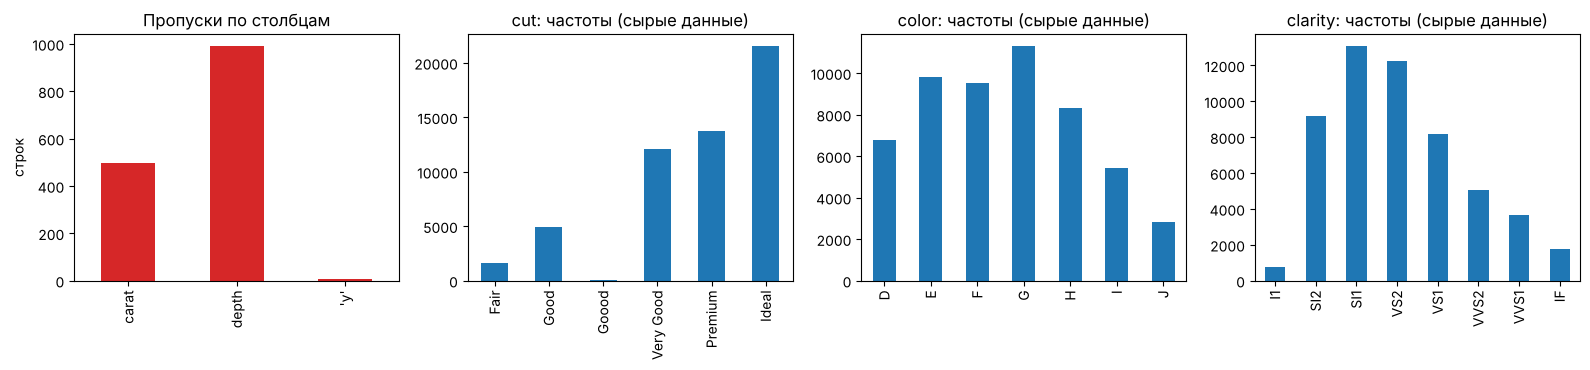

In [51]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
miss = df_copy.isna().sum()
miss[miss > 0].plot.bar(ax=axes[0], color='tab:red')
axes[0].set(title='Пропуски по столбцам', ylabel='строк')
raw_orders = {'cut': ['Fair', 'Good', 'Goood', 'Very Good', 'Premium', 'Ideal'],   # порядковые признаки —
              'color': list('DEFGHIJ'),                                             # рисуем в их естественном порядке
              'clarity': ['I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', 'IF']}
for ax, col in zip(axes[1:], ['cut', 'color', 'clarity']):
    df_copy[col].value_counts().reindex(raw_orders[col]).plot.bar(ax=ax, color='tab:blue')
    ax.set(title=f'{col}: частоты (сырые данные)', xlabel='')
plt.tight_layout(); plt.show()

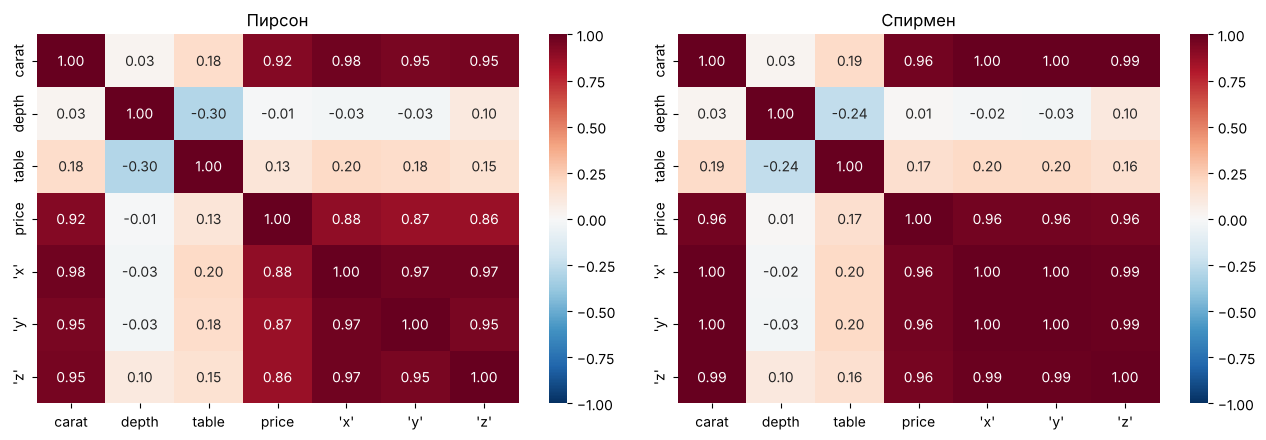

In [52]:
num_cols = df_copy.select_dtypes('number').columns
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(df_copy[num_cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Пирсон')
sns.heatmap(df_copy[num_cols].corr(method='spearman'), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Спирмен')
plt.tight_layout(); plt.show()

**Что показывают отчёт и ручной обзор (сырые данные):**

* 53 940 строк и 10 столбцов: 7 числовых и 3 категориальных (`cut`, `color`, `clarity`). Пропущенных ячеек 1493, это 0.3 %: в `depth` 990, в `carat` 498, в `y` 5.
* Дубликаты в двух программах считаются по-разному. `df.duplicated()` находит 135 лишних копий, а profiling пишет «132 duplicate rows», потому что считает различные строки, у которых есть копии. Это одни и те же данные.
* В `cut` есть опечатка `Goood` (80 строк), это видно на столбчатой диаграмме частот. В `x`, `y`, `z` встречаются нули (8, 7 и 20 строк), то есть ошибки измерения, ими занимается домашнее задание.
* Profiling предупреждает о высокой корреляции между `carat`, `price`, `x`, `y`, `z`. На тепловых картах это видно: коэффициенты Пирсона между ними 0.86–0.98, Спирмена 0.96–1.00. `depth` и `table` почти не коррелируют ни с чем, кроме друг друга (r = −0.30).

# Домашнее задание

## 1) x, y, z

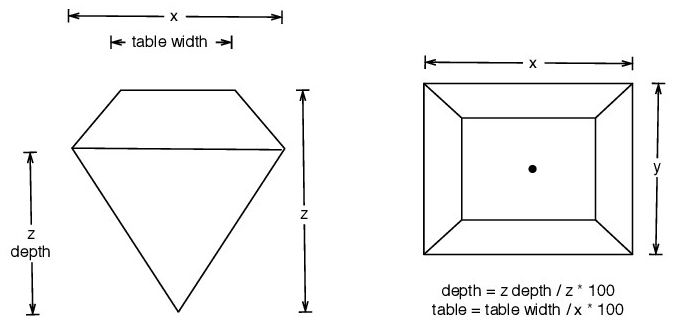

In [53]:
df.columns

Index(['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', ''x'',
       ''y'', ''z''],
      dtype='str')

Переименуем колонки

In [54]:
df = df.rename(columns={"'x'" : 'x', "'y'" : 'y', "'z'" : 'z'})
df.columns

Index(['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'x', 'y',
       'z'],
      dtype='str')

### Задание 1

Для каждого из трех столбцов (`x`, `y`, `z`) вычислите медианное значение. В ответ запишите максимальное из полученных чисел без округлений.

In [55]:
medians_xyz = df[['x', 'y', 'z']].median()
print(medians_xyz)
print('Максимальная из медиан:', medians_xyz.max())

x    5.70
y    5.71
z    3.53
dtype: float64
Максимальная из медиан: 5.71


**Ответ: 5.71** (медиана `y`; у `x` 5.70, у `z` 3.53).

Медианы `x` и `y` почти совпадают: ширина и длина камня в плане близки. `z` (высота) заметно меньше. Медианы посчитаны до удаления нулевых размеров, в том порядке, в каком идут задания, и единичные нули на них не влияют.

Для каждого из этих столбцов вычислите минимальное значение.

In [56]:
np.min(df['x']), np.min(df['y']), np.min(df['z'])

(np.float64(0.0), np.float64(0.0), np.float64(0.0))

Нулевые размеры - явно ошибки.

### Задание 2

Выведите на экран все строки таблицы (только столбцы `x`,`y`,`z`), в которых хотя бы одна из координат равна нулю.

Сколько таких строк?

In [57]:
zero_mask = (df[['x', 'y', 'z']] == 0).any(axis=1)
print('Строк, где хотя бы один размер равен 0:', zero_mask.sum())
print('Нулей по столбцам:', (df[['x', 'y', 'z']] == 0).sum().to_dict())
df.loc[zero_mask, ['x', 'y', 'z']]

Строк, где хотя бы один размер равен 0: 19
Нулей по столбцам: {'x': 7, 'y': 6, 'z': 19}


,x,y,z
2201,6.55,6.48,0.0
2308,6.66,6.60,0.0
4779,6.50,6.47,0.0
5458,6.50,6.47,0.0
10146,7.15,7.04,0.0
11158,0.00,6.62,0.0
11937,0.00,0.00,0.0
13572,6.88,6.83,0.0
15916,0.00,0.00,0.0
24342,8.49,8.45,0.0


**Ответ: 19 строк.**

Во всех 19 строках `z = 0`. В 6 из них нулевые все три размера, ещё в одной ноль у `x` и `z`. Камень с нулевым размером физически невозможен, так что это пропуски, закодированные нулём. На гистограммах выше такие значения выглядели отдельным столбиком около нуля.

### Задание 3

Удалите из таблицы эти строки. Сколько строк осталось в таблице?

In [58]:
df = df[~zero_mask].reset_index(drop=True)
print('Осталось строк:', len(df))
print('Минимумы после удаления:', df[['x', 'y', 'z']].min().to_dict())

Осталось строк: 53786
Минимумы после удаления: {'x': 3.73, 'y': 3.68, 'z': 1.07}


**Ответ: 53 786 строк** (53 805 − 19). Нулевых размеров больше нет: минимумы `x`, `y`, `z` теперь 3.73, 3.68 и 1.07 мм. Удаление выбрано потому, что таких строк всего 0.04 % и восстановить размеры по ним нечем.

### Задание 4

Вычислите корреляцию между каждым из этих столбцов и `price`. Какой столбец коррелирует с ценой алмаза больше всего?

x    0.8872
y    0.8677
z    0.8681
dtype: float64
Сильнее всего с ценой коррелирует: x
Максимумы размеров, мм: {'x': 10.74, 'y': 58.9, 'z': 31.8}


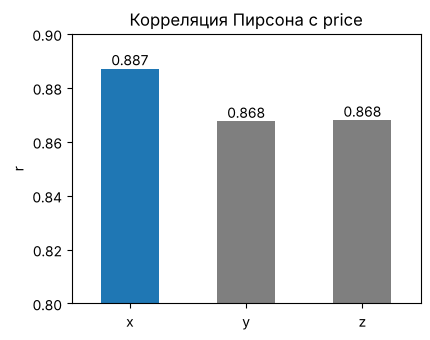

In [59]:
corr_xyz = df[['x', 'y', 'z']].corrwith(df['price'])
print(corr_xyz.round(4))
print('Сильнее всего с ценой коррелирует:', corr_xyz.idxmax())
print('Максимумы размеров, мм:', df[['x', 'y', 'z']].max().to_dict())

ax = corr_xyz.plot.bar(figsize=(4.5, 3.5), color=['tab:blue', 'tab:gray', 'tab:gray'], rot=0)
ax.bar_label(ax.containers[0], fmt='%.3f')
ax.set(ylim=(0.8, 0.9), title='Корреляция Пирсона с price', ylabel='r')
plt.show()

**Ответ: `x`** (r = 0.887; у `y` и `z` по 0.868).

Все три размера сильно коррелируют с ценой, и разница между ними небольшая. Одна из видимых причин в том, что у `y` и `z` остались единичные выбросы: максимум `y` 58.9 мм, `z` 31.8 мм при типичных 3–9 мм. Коэффициент Пирсона к таким точкам чувствителен, а у `x` максимум 10.74 мм, без выбросов.

### Задание 5

Постройте scatter-plot для отражения зависимости между ценой алмаза и координатой, наиболее с ней коррелирующей. На какую зависимость она больше всего похожа?

R² прямой price ~ x:                     0.787
R² прямой log(price) ~ x (экспонента):   0.923


R² прямой log(price) ~ log(x) (степень): 0.933 | показатель степени: 5.06


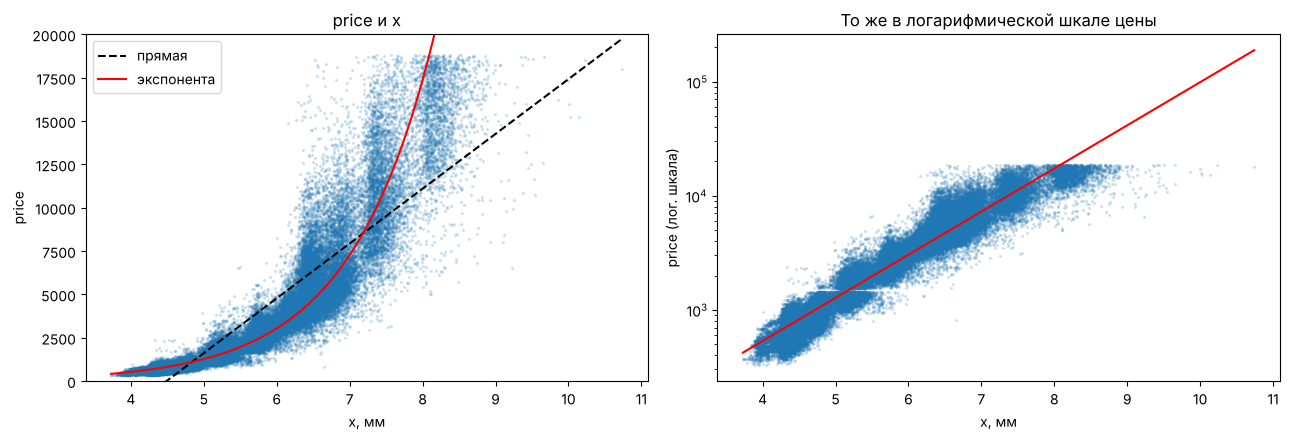

In [60]:
# прямая price ~ x и прямая log(price) ~ x (то есть экспонента price = exp(a + b·x))
lin = np.polyfit(df['x'], df['price'], 1)
expo = np.polyfit(df['x'], np.log(df['price']), 1)
power = np.polyfit(np.log(df['x']), np.log(df['price']), 1)

def r2(y, y_hat):
    return 1 - ((y - y_hat) ** 2).sum() / ((y - y.mean()) ** 2).sum()

log_price = np.log(df['price'])
print('R² прямой price ~ x:                    ', round(r2(df['price'], np.polyval(lin, df['x'])), 3))
print('R² прямой log(price) ~ x (экспонента):  ', round(r2(log_price, np.polyval(expo, df['x'])), 3))
print('R² прямой log(price) ~ log(x) (степень):', round(r2(log_price, np.polyval(power, np.log(df['x']))), 3),
      '| показатель степени:', round(power[0], 2))

grid = np.linspace(df['x'].min(), df['x'].max(), 200)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(df['x'], df['price'], s=2, alpha=0.15)
axes[0].plot(grid, np.polyval(lin, grid), 'k--', label='прямая')
axes[0].plot(grid, np.exp(np.polyval(expo, grid)), 'r', label='экспонента')
axes[0].set(xlabel='x, мм', ylabel='price', ylim=(0, 20000), title='price и x')
axes[0].legend()
axes[1].scatter(df['x'], df['price'], s=2, alpha=0.15)
axes[1].plot(grid, np.exp(np.polyval(expo, grid)), 'r')
axes[1].set_yscale('log'); axes[1].set(xlabel='x, мм', ylabel='price (лог. шкала)',
                                       title='То же в логарифмической шкале цены')
plt.tight_layout(); plt.show()

**Ответ: больше всего похоже на экспоненциальную зависимость** (нелинейный, ускоряющийся рост). При малых `x` цена растёт медленно, при больших быстро, и облако изгибается вверх. Прямая этот изгиб не повторяет: при малых `x` она уходит в отрицательные цены, R² = 0.787. Если перевести цену в логарифмическую шкалу (правый график), облако почти выпрямляется: прямая `log(price) ~ x` даёт R² = 0.923, что и соответствует экспоненте. Степенная кривая `price ~ x^5.06` описывает облако примерно так же (R² = 0.933 в лог. шкале), то есть по форме это быстрый нелинейный рост, и линейной модели здесь недостаточно. Справа облако упирается в «потолок» цены (максимум в данных 18 823), поэтому при `x` > 8 мм экспонента уходит выше точек. Кроме того, при одном и том же `x` разброс цен большой, особенно у крупных камней.

### Задание 6

Какой процент среди всех алмазов имеет `x` и `y` размеры, превышающие средние значения (по `x` и `y`)? Ответ округлите до целого числа.

Средние: x = 5.732, y = 5.735
Доля алмазов с x и y выше средних: 47.38 % → 47 %


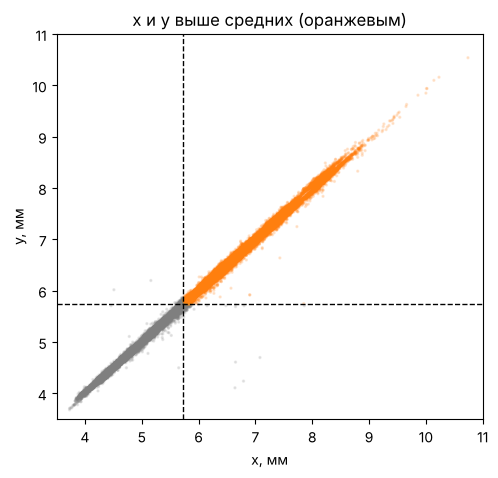

In [61]:
x_mean, y_mean = df['x'].mean(), df['y'].mean()
above = (df['x'] > x_mean) & (df['y'] > y_mean)
share_pct = 100 * above.mean()
print(f'Средние: x = {x_mean:.3f}, y = {y_mean:.3f}')
print(f'Доля алмазов с x и y выше средних: {share_pct:.2f} % → {round(share_pct)} %')

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(df['x'], df['y'], s=2, alpha=0.15, c=np.where(above, 'tab:orange', 'tab:gray'))
ax.axvline(x_mean, color='k', ls='--', lw=1); ax.axhline(y_mean, color='k', ls='--', lw=1)
ax.set(xlim=(3.5, 11), ylim=(3.5, 11), xlabel='x, мм', ylabel='y, мм',
       title='x и y выше средних (оранжевым)')
plt.show()

**Ответ: 47 %** (47.38 %).

`x` и `y` почти всегда идут вместе, точки лежат вдоль диагонали, поэтому условие «оба выше среднего» почти совпадает с условием «`x` выше среднего». Доля получилась меньше половины, потому что распределения размеров скошены вправо и среднее (5.73) чуть выше медианы (5.70).

### Задание 7

Какая доля среди крупных алмазов имеет `z`-размеры, меньшие медианного? Ответ округлите до четырех знаков после запятой.

Крупных алмазов: 18814 | медиана z по всем алмазам: 3.53
Доля крупных с z меньше медианы: 0.0002 (4 шт.)
(если брать медиану z среди крупных: 0.4907 )


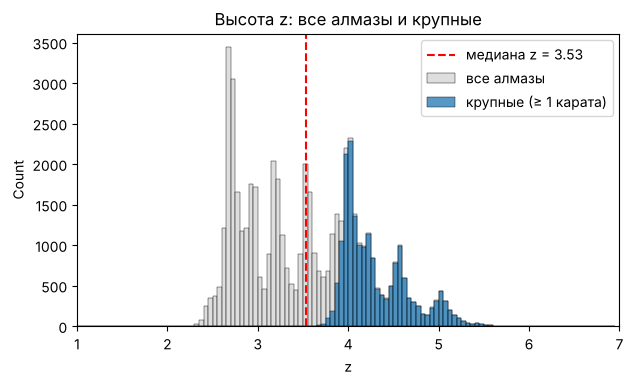

In [62]:
large = df[df['carat'] >= 1]              # крупные — от 1 карата (определение выше)
z_median = df['z'].median()               # медиана z по всем алмазам
below = large['z'] < z_median
print('Крупных алмазов:', len(large), '| медиана z по всем алмазам:', z_median)
print('Доля крупных с z меньше медианы:', round(below.mean(), 4), f'({below.sum()} шт.)')
# для сравнения — если сравнивать с медианой z среди самих крупных
print('(если брать медиану z среди крупных:', round((large['z'] < large['z'].median()).mean(), 4), ')')

plt.figure(figsize=(7, 3.8))
z_bins = np.arange(1, 7, 0.05)    # общие корзины для обеих гистограмм
sns.histplot(df['z'], bins=z_bins, color='lightgray', label='все алмазы')
sns.histplot(large['z'], bins=z_bins, color='tab:blue', label='крупные (≥ 1 карата)')
plt.axvline(z_median, color='r', ls='--', label=f'медиана z = {z_median}')
plt.xlim(1, 7); plt.legend(); plt.title('Высота z: все алмазы и крупные')
plt.show()

**Ответ: 0.0002** (4 камня из 18 814 крупных).

«Медианное» значение я понимаю так же, как в задании 1, то есть как медиану `z` по всем алмазам (3.53 мм). На гистограмме крупные камни почти целиком лежат правее этой линии, ниже неё только 4 штуки. Если бы имелась в виду медиана `z` среди самих крупных, доля по определению медианы была бы около половины (0.4907), поэтому округление до четырёх знаков и подсказывает первое прочтение.

## 2) Color

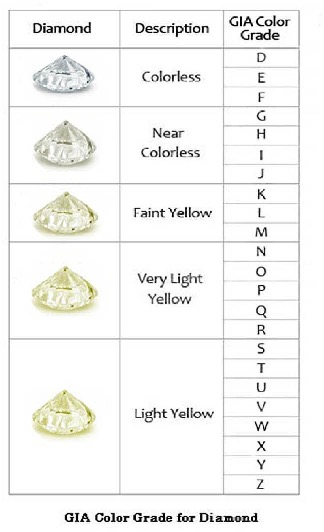

### Задание 8

К каким категориям (Description) из градации выше относятся алмазы в данных?

Цвета в данных: ['D', 'E', 'F', 'G', 'H', 'I', 'J']
color
Near Colorless    27736
Colorless         26050
Name: count, dtype: int64


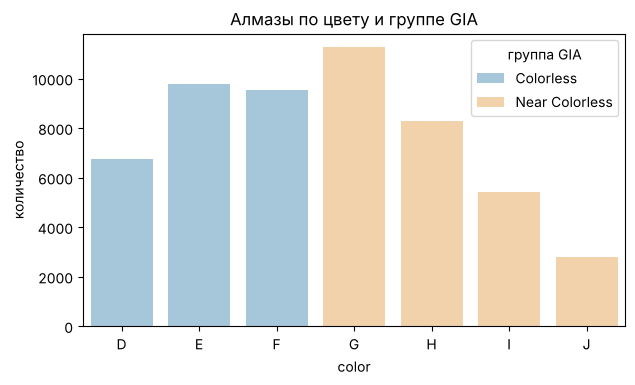

In [63]:
gia_description = {}
for letters, desc in [('DEF', 'Colorless'), ('GHIJ', 'Near Colorless'), ('KLM', 'Faint Yellow'),
                      ('NOPQR', 'Very Light Yellow'), ('STUVWXYZ', 'Light Yellow')]:
    for letter in letters:
        gia_description[letter] = desc

color_order = sorted(df['color'].unique())     # D — лучший цвет, J — худший из имеющихся
print('Цвета в данных:', color_order)
print(df['color'].map(gia_description).value_counts())

plt.figure(figsize=(7, 3.8))
ax = sns.countplot(x='color', data=df, order=color_order, hue=df['color'].map(gia_description),
                   palette={'Colorless': '#9ecae1', 'Near Colorless': '#fdd49e'})
ax.set(title='Алмазы по цвету и группе GIA', ylabel='количество'); ax.legend(title='группа GIA')
plt.show()

**Ответ: Colorless (D, E, F) и Near Colorless (G, H, I, J).**

В данных 7 цветов, от D до J. Цветов из групп Faint Yellow, Very Light Yellow и Light Yellow (K–Z) нет совсем. Near Colorless камней немного больше (27 736 против 26 050).

### Задание 9

Нарисуйте график, отражающий зависимость стоимости алмазов от его категории цвета.

Алмазы какого цвета стоят дороже остальных?

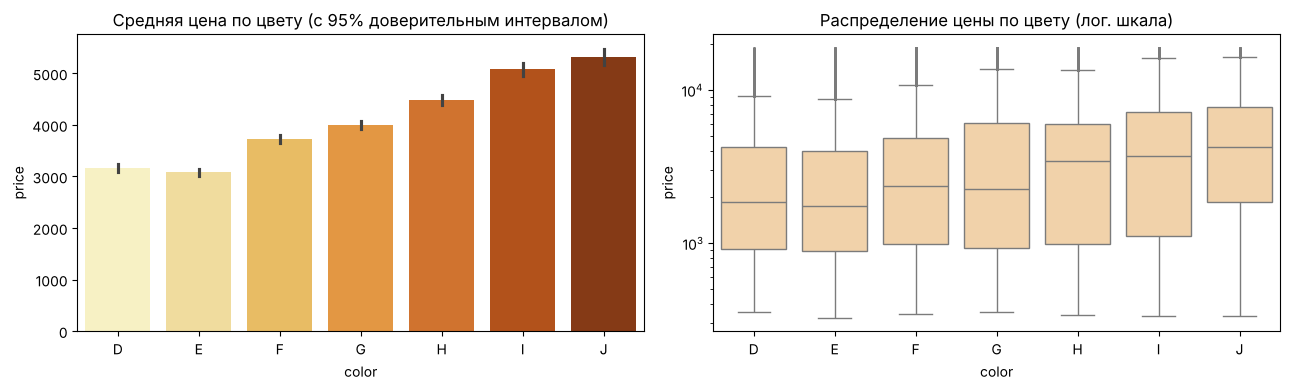

,PriceMean,PriceMedian,CaratMedian
color,,,
D,3172.26,1842.0,0.54
E,3079.38,1741.0,0.54
F,3726.50,2345.0,0.70
G,3999.42,2242.0,0.70
H,4478.86,3449.5,0.90
I,5082.22,3721.5,1.00
J,5326.42,4234.5,1.11


In [64]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(x='color', y='price', data=df, order=color_order, hue='color', hue_order=color_order,
            palette='YlOrBr', legend=False, ax=axes[0])
axes[0].set_title('Средняя цена по цвету (с 95% доверительным интервалом)')
sns.boxplot(x='color', y='price', data=df, order=color_order, color='#fdd49e', fliersize=1, ax=axes[1])
axes[1].set_yscale('log'); axes[1].set_title('Распределение цены по цвету (лог. шкала)')
plt.tight_layout(); plt.show()

(df.groupby('color')
   .agg(PriceMean=('price', 'mean'), PriceMedian=('price', 'median'), CaratMedian=('carat', 'median'))
   .round(2))

**Ответ: J.** Средняя цена 5326.4, медианная 4234.5, по обоим показателям это максимум.

На графике средняя цена почти монотонно растёт от лучших цветов к худшему: E и D самые дешёвые (3079 и 3172), J самый дорогой. В таблице видно, что так же меняется и медианный вес (от 0.54 карата у D/E до 1.11 у J). Группы цвета различаются по весу, и по этому графику нельзя сказать, что «жёлтый цвет делает алмаз дороже», мы видим только состав групп.

### Задание 10

Для каждого цвета алмаза вычислите медианную стоимость и медианный вес (в каратах). Отсортируйте полученную при помощи groupby таблицу по убыванию медианной стоимости.

Верно ли, что при убывании PriceMedian, сгруппированной по цвету, CaratMedian также убывает? (не возрастает)

       PriceMedian  CaratMedian
color                          
J           4234.5         1.11
I           3721.5         1.00
H           3449.5         0.90
F           2345.0         0.70
G           2242.0         0.70
D           1842.0         0.54
E           1741.0         0.54

CaratMedian не возрастает при убывании PriceMedian: True


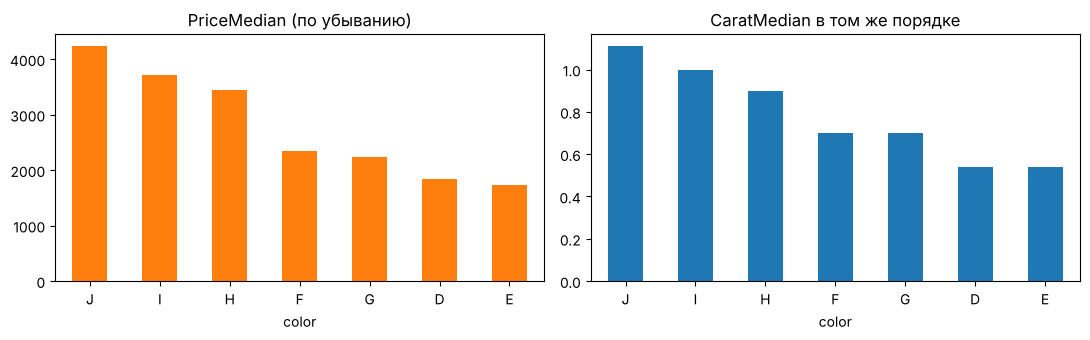

In [65]:
color_stats = (df.groupby('color')
                 .agg(PriceMedian=('price', 'median'), CaratMedian=('carat', 'median'))
                 .sort_values(by='PriceMedian', ascending=False))
print(color_stats)
print('\nCaratMedian не возрастает при убывании PriceMedian:', color_stats['CaratMedian'].is_monotonic_decreasing)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharex=True)
color_stats['PriceMedian'].plot.bar(ax=axes[0], color='tab:orange', rot=0, title='PriceMedian (по убыванию)')
color_stats['CaratMedian'].plot.bar(ax=axes[1], color='tab:blue', rot=0, title='CaratMedian в том же порядке')
plt.tight_layout(); plt.show()

**Ответ: верно.**

В порядке убывания медианной цены J → I → H → F → G → D → E медианный вес идёт так: 1.11 → 1.00 → 0.90 → 0.70 → 0.70 → 0.54 → 0.54. Он ни разу не возрастает, хотя есть равенства (F = G и D = E). Метод `is_monotonic_decreasing` в pandas как раз проверяет нестрогое убывание. Заодно видно, что по медианной цене F (2345) стоит выше G (2242), то есть порядок не совпадает с алфавитным.

### Задание 11

Вычислите среднюю стоимость алмазов по каждой тройке категорий (`cut`,`color`,`clarity`). Какие алмазы дороже остальных?

В ответе запишите тройку названий в скобках через запятую, без кавычек и пробелов. Например, (Premium,D,IF)

PriceMean  Count
cut       color clarity                  
Very Good D     IF        10298.26     23
Good      D     IF        10030.33      9
Ideal     J     I1         9454.00      2
Premium   D     IF         9056.50     10
          J     SI2        7550.29    161
Fair      D     I1         7383.00      4
Premium   J     VVS1       7244.38     24
Ideal     I     SI2        7204.96    273
Premium   I     SI2        7161.35    307
                VS2        7132.94    313

Самые дорогие в среднем: (Very Good,D,IF)


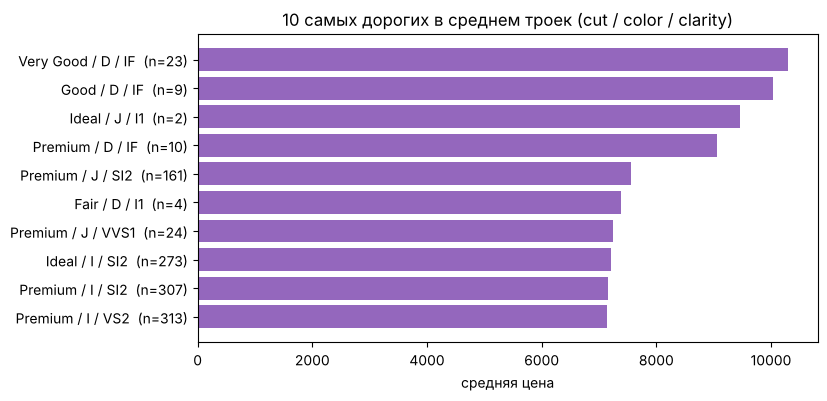

In [66]:
triple = (df.groupby(['cut', 'color', 'clarity'])['price']
            .agg(PriceMean='mean', Count='size')
            .sort_values('PriceMean', ascending=False))
display(triple.head(10).round(2))

best = triple.index[0]
print(f'Самые дорогие в среднем: ({best[0]},{best[1]},{best[2]})')

top = triple.head(10)
labels = [f'{c} / {col} / {cl}  (n={n})' for (c, col, cl), n in zip(top.index, top['Count'])]
plt.figure(figsize=(8, 4))
plt.barh(labels[::-1], top['PriceMean'][::-1], color='tab:purple')
plt.xlabel('средняя цена'); plt.title('10 самых дорогих в среднем троек (cut / color / clarity)')
plt.show()

**Ответ: (Very Good,D,IF).** Средняя цена 10 298.26, в группе 23 алмаза.

Пробелы в ответе убраны только между элементами тройки, а `Very Good` пишется с пробелом, это само название огранки. При переходе к тройкам категорий группы становятся маленькими: на втором месте (Good, D, IF) всего 9 камней, на третьем (Ideal, J, I1) только 2. На таких группах среднее легко сдвигается одним дорогим камнем, поэтому подписи `n` на графике нужно читать вместе со средней ценой.

## Итоги практики

| Задание | Ответ |
|---|---|
| 1. Медиана `y` (заполнение пропусков) | **5.71** |
| 2. Максимальный вес огранки Fair | **5.01** карата |
| 3. Доля с оптимальными `table` и `depth` | **0.62** |
| 4. Чья медианная цена больше | **всех алмазов** (2401 > 2215) |
| 5. Число градаций `clarity` | **8** |
| 6. Алмазов VVS (VVS1 + VVS2) | **8704** |
| 7. Самая дорогая в среднем категория `clarity` | **SI2** |
| 8. Огранка с наибольшей средней ценой в паре (cut, clarity) | **Premium** (с SI2) |
| ДЗ 1. Максимальная из медиан `x`, `y`, `z` | **5.71** |
| ДЗ 2. Строк с нулевым размером | **19** |
| ДЗ 3. Строк после удаления | **53 786** |
| ДЗ 4. Сильнее всего коррелирует с ценой | **x** (r = 0.887) |
| ДЗ 5. Вид зависимости `price` от `x` | **экспоненциальная** (нелинейный ускоряющийся рост) |
| ДЗ 6. Доля с `x` и `y` выше средних | **47 %** |
| ДЗ 7. Доля крупных с `z` меньше медианы | **0.0002** |
| ДЗ 8. Группы цвета в данных | **Colorless (D–F), Near Colorless (G–J)** |
| ДЗ 9. Самый дорогой цвет | **J** |
| ДЗ 10. CaratMedian не возрастает при убывании PriceMedian | **верно** |
| ДЗ 11. Самая дорогая тройка | **(Very Good,D,IF)** |

Главное, что видно в данных: цена сильно и нелинейно растёт вместе с весом и размерами камня. При этом простые сравнения «цена по огранке / прозрачности / цвету» дают на первый взгляд парадоксальную картину (лучшие категории дешевле). Группы этих категорий заметно различаются по весу, поэтому по таким графикам я только описываю состав групп и не делаю выводов о связи.